In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('superstore_unclean.csv')

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [2]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,...,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0.0,91.9508
1,4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,...,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0.0,53.8608
2,4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,...,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0.0,129.3480
3,34,US-2023-103366,2023-01-15,2023-01-17,First Class,EH-13990,Erica Hackney,Consumer,United States,Roswell,...,30076,South,TEC-AC-10003628,Technology,Accessories,Logitech 910-002974 M325 Wireless Mouse for We...,149.95,5,0.0,65.9780
4,2927,US-2024-124219,2024-08-07,2024-08-08,First Class,KW-16570,Kelly Williams,Consumer,United States,Kirkwood,...,63122,Central,FUR-FU-10000305,Furniture,Furnishings,"Tenex V2T-RE Standard Weight Series Chair Mat,...",212.94,3,0.0,34.0704


In [3]:
print("Number of Rows and Columns:", df.shape)

Number of Rows and Columns: (10214, 21)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10214 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10214 non-null  int64  
 1   Order ID        10214 non-null  object 
 2   Order Date      10214 non-null  object 
 3   Ship Date       10214 non-null  object 
 4   Ship Mode       10214 non-null  object 
 5   Customer ID     10214 non-null  object 
 6   Customer Name   10214 non-null  object 
 7   Segment         10214 non-null  object 
 8   Country/Region  10214 non-null  object 
 9   City            10214 non-null  object 
 10  State/Province  10214 non-null  object 
 11  Postal Code     10184 non-null  object 
 12  Region          10214 non-null  object 
 13  Product ID      10214 non-null  object 
 14  Category        10214 non-null  object 
 15  Sub-Category    10214 non-null  object 
 16  Product Name    10214 non-null  object 
 17  Sales           10194 non-null 

In [5]:
df.describe()

,Row ID,Quantity,Discount,Profit
count,10214.000000,10214.000000,10214.000000,10214.000000
mean,5096.372528,3.781868,0.155452,28.641109
std,2943.754048,2.244482,0.206313,232.241551
min,1.000000,-8.000000,0.000000,-6599.978000
25%,2547.250000,2.000000,0.000000,1.753775
50%,5095.500000,3.000000,0.200000,8.687750
75%,7645.750000,5.000000,0.200000,29.282175
max,10194.000000,14.000000,0.800000,8399.976000


In [6]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')


In [7]:
print(df.isnull().sum())

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State/Province     0
Postal Code       30
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales             20
Quantity           0
Discount           0
Profit             0
dtype: int64


In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 20


In [9]:
df = df.drop_duplicates()

print("Duplicates Removed Successfully")
print("Shape After Removing Duplicates:", df.shape)

Duplicates Removed Successfully
Shape After Removing Duplicates: (10194, 21)


In [10]:
df['Sales'] = df['Sales'].astype('string')

df['Sales'] = df['Sales'].str.replace('$', '', regex=False)
df['Sales'] = df['Sales'].str.replace(',', '', regex=False)

df['Sales'] = pd.to_numeric(
    df['Sales'],
    errors='coerce'
)

print(df['Sales'].dtype)

Float64


In [11]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='mixed',
    errors='coerce'
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    format='mixed',
    errors='coerce'
)

print(df[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [12]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State/Province     0
Postal Code       30
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales             20
Quantity           0
Discount           0
Profit             0
dtype: int64


In [13]:
df = df.dropna(subset=['Sales'])

print("Missing Sales Records Removed")
print(df.shape)

Missing Sales Records Removed
(10174, 21)


In [14]:
print(df['Ship Mode'].value_counts())

Ship Mode
Standard Class       5626
Second Class         1803
First Class          1425
Same Day              509
standard class        124
  Standard Class      123
STANDARD CLASS        120
 standard class       117
 second class          47
second class           42
SECOND CLASS           41
  Second Class         41
FIRST CLASS            34
 first class           30
  First Class          27
first class            27
SAME DAY               10
 same day              10
  Same Day              9
same day                9
Name: count, dtype: int64


In [15]:
df['Ship Mode'] = (
    df['Ship Mode']
    .str.strip()
    .str.title()
)

df['Region'] = (
    df['Region']
    .str.strip()
    .str.title()
)

In [16]:
print("Ship Mode Values:")
print(df['Ship Mode'].value_counts())

print("\nRegion Values:")
print(df['Region'].value_counts())

Ship Mode Values:
Ship Mode
Standard Class    6110
Second Class      1974
First Class       1543
Same Day           547
Name: count, dtype: int64

Region Values:
Region
West       3244
East       2983
Central    2329
South      1618
Name: count, dtype: int64


In [17]:
negative_quantity = df[df['Quantity'] < 0]

print("Negative Quantity Records:")
display(negative_quantity)

Negative Quantity Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1474,2992,US-2024-128090,2024-08-16,2024-08-22,Standard Class,JM-15865,John Murray,Consumer,United States,Phoenix,...,85023,West,TEC-PH-10002624,Technology,Phones,Samsung Galaxy S4 Mini,1879.96,-5,0.2,211.4955
1646,8716,US-2026-163300,2026-09-15,2026-09-21,Standard Class,ES-14020,Erica Smith,Consumer,United States,Los Angeles,...,90049,West,OFF-BI-10004390,Office Supplies,Binders,GBC DocuBind 200 Manual Binding Machine,2357.488,-7,0.2,884.0580
1786,9350,US-2026-167941,2026-11-06,2026-11-09,Second Class,JF-15565,Jill Fjeld,Consumer,United States,Fayetteville,...,28314,South,OFF-BI-10002827,Office Supplies,Binders,Avery Durable Poly Binders,13.272,-8,0.7,-10.6176
2201,1288,US-2023-166891,2023-10-04,2023-10-06,First Class,CC-12220,Chris Cortes,Consumer,United States,New York City,...,10024,East,FUR-CH-10003298,Furniture,Chairs,Office Star - Contemporary Task Swivel chair w...,589.41,-5,0.1,-6.5490
5401,5149,US-2025-103107,2025-07-04,2025-07-04,Same Day,RB-19465,Rick Bensley,Home Office,United States,Seattle,...,98103,West,FUR-FU-10000221,Furniture,Furnishings,"Master Caster Door Stop, Brown",25.4,-5,0.0,8.6360
6020,8368,US-2026-163069,2026-08-18,2026-08-21,Second Class,PJ-19015,Pauline Johnson,Consumer,United States,Columbus,...,43229,East,OFF-AR-10001419,Office Supplies,Art,Newell 325,9.912,-3,0.2,1.2390
6472,5678,US-2025-102162,2025-09-11,2025-09-16,Standard Class,JF-15565,Jill Fjeld,Consumer,United States,Newport News,...,23602,South,OFF-EN-10002312,Office Supplies,Envelopes,#10 Self-Seal White Envelopes,11.09,-1,0.0,5.4341
7205,6746,US-2025-168620,2025-12-24,2025-12-28,Second Class,RB-19795,Ross Baird,Home Office,United States,Charlotte,...,28205,South,OFF-ST-10003716,Office Supplies,Storage,Tennsco Double-Tier Lockers,540.048,-3,0.2,-47.2542
8226,594,US-2023-109162,2023-06-08,2023-06-12,Standard Class,KE-16420,Katrina Edelman,Corporate,United States,Bristol,...,37620,South,FUR-CH-10002647,Furniture,Chairs,"Situations Contoured Folding Chairs, 4/Set",170.352,-3,0.2,10.6470
8806,2383,US-2024-133837,2024-04-13,2024-04-18,Standard Class,TH-21100,Thea Hendricks,Consumer,United States,Glendale,...,85301,West,OFF-ST-10000344,Office Supplies,Storage,"Neat Ideas Personal Hanging Folder Files, Black",10.744,-1,0.2,0.8058


In [18]:
invalid_dates = df[
    df['Ship Date'] < df['Order Date']
]

print("Invalid Shipping Date Records:")
display(invalid_dates)

Invalid Shipping Date Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
218,3394,US-2024-134859,2024-10-04,2024-09-29,Standard Class,JK-16120,Julie Kriz,Home Office,United States,Philadelphia,...,19134,East,FUR-FU-10003623,Furniture,Furnishings,"DataProducts Ampli Magnifier Task Lamp, Black,",64.944,3,0.2,6.4944
612,3018,US-2024-165624,2024-08-23,2024-08-18,Standard Class,FH-14350,Fred Harton,Consumer,United States,Atlanta,...,30318,South,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94,3,0.0,152.0232
2729,1644,US-2023-144624,2023-11-19,2023-11-14,Standard Class,JM-15865,John Murray,Consumer,United States,Jamestown,...,14701,East,TEC-PH-10002885,Technology,Phones,Apple iPhone 5,4548.81,7,0.0,1228.1787
2853,373,US-2023-110849,2023-04-18,2023-04-13,Standard Class,JL-15835,John Lee,Consumer,United States,Los Angeles,...,90049,West,OFF-AR-10000657,Office Supplies,Art,"Binney & Smith inkTank Desk Highlighter, Chise...",10.75,5,0.0,3.5475
3909,9582,US-2026-120404,2026-11-20,2026-11-15,Second Class,KH-16330,Katharine Harms,Corporate,United States,New York City,...,10035,East,TEC-PH-10001363,Technology,Phones,Apple iPhone 5S,569.99,1,0.0,170.9970
4901,758,US-2023-164182,2023-07-14,2023-07-09,Standard Class,ST-20530,Shui Tom,Consumer,United States,Philadelphia,...,19140,East,TEC-PH-10002070,Technology,Phones,Griffin GC36547 PowerJolt SE Lightning Charger,13.494,1,0.4,-2.2490
6873,7334,US-2026-145877,2026-04-01,2026-03-27,Second Class,AS-10090,Adam Shillingsburg,Consumer,United States,Springfield,...,65807,Central,OFF-EN-10001990,Office Supplies,Envelopes,Staple envelope,28.4,5,0.0,13.3480
8288,2495,US-2024-112130,2024-05-03,2024-04-28,Standard Class,SV-20785,Stewart Visinsky,Consumer,United States,Philadelphia,...,19140,East,OFF-AR-10001468,Office Supplies,Art,Sanford Prismacolor Professional Thick Lead Ar...,59.904,2,0.2,14.2272
8305,2531,US-2024-162607,2024-05-12,2024-05-07,Standard Class,RO-19780,Rose O'Brian,Consumer,United States,Seattle,...,98115,West,OFF-BI-10002949,Office Supplies,Binders,Prestige Round Ring Binders,14.592,3,0.2,4.9248


In [19]:
df = df[
    df['Ship Date'] >= df['Order Date']
].copy()

print("Invalid Shipping Dates Removed")

Invalid Shipping Dates Removed


In [20]:
print("Final Dataset Information")

df.info()

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Final Dataset Information
<class 'pandas.core.frame.DataFrame'>
Index: 10165 entries, 0 to 10213
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10165 non-null  int64         
 1   Order ID        10165 non-null  object        
 2   Order Date      10165 non-null  datetime64[ns]
 3   Ship Date       10165 non-null  datetime64[ns]
 4   Ship Mode       10165 non-null  object        
 5   Customer ID     10165 non-null  object        
 6   Customer Name   10165 non-null  object        
 7   Segment         10165 non-null  object        
 8   Country/Region  10165 non-null  object        
 9   City            10165 non-null  object        
 10  State/Province  10165 non-null  object        
 11  Postal Code     10135 non-null  object        
 12  Region          10165 non-null  object        
 13  Product ID      10165 non-null  object        
 14  Category        10165 non-null  o

In [21]:
sales_by_subcategory = df.groupby(
    'Sub-Category'
)['Sales'].sum().sort_values(ascending=False)

print(sales_by_subcategory)

Sub-Category
Chairs          335768.249
Phones          326660.728
Storage         224220.014
Tables          208020.182
Binders         207012.011
Machines        189925.031
Accessories     166640.422
Copiers          150745.29
Bookcases      115288.9053
Appliances      107670.241
Furnishings      95533.178
Paper            79409.252
Supplies         46725.498
Art              27566.586
Envelopes        16456.004
Labels           12678.816
Fasteners         8532.236
Name: Sales, dtype: Float64


In [22]:
top_3 = sales_by_subcategory.head(3)

print("Top 3 Highest Selling Sub-Categories:")
print(top_3)

Top 3 Highest Selling Sub-Categories:
Sub-Category
Chairs     335768.249
Phones     326660.728
Storage    224220.014
Name: Sales, dtype: Float64


In [23]:
segment_sales = df.groupby('Segment')['Sales'].agg(
    ['sum', 'mean', 'count']
)

print(segment_sales)

                     sum        mean  count
Segment                                    
Consumer     1164367.166  221.320503   5261
Corporate    714786.6948  231.772599   3084
Home Office  439698.7825  241.592738   1820


In [24]:
category_count = df['Category'].value_counts()

print("Category Counts:")
print(category_count)

Category Counts:
Category
Office Supplies    6108
Furniture          2199
Technology         1858
Name: count, dtype: int64


In [25]:
profit_analysis = df.groupby('Sub-Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

print(profit_analysis.sort_values(
    by='Total_Sales',
    ascending=False
))

              Total_Sales  Total_Profit
Sub-Category                           
Chairs         335768.249    27223.5323
Phones         326660.728    43648.9382
Storage        224220.014    21287.3639
Tables         208020.182   -17753.2061
Binders        207012.011    31312.5267
Machines       189925.031     3461.9769
Accessories    166640.422    41740.6136
Copiers         150745.29    56093.9365
Bookcases     115288.9053    -3533.2718
Appliances     107670.241    18177.4612
Furnishings     95533.178    13885.2486
Paper           79409.252    34463.0526
Supplies        46725.498    -1171.3945
Art             27566.586     6629.0648
Envelopes       16456.004     6954.0155
Labels          12678.816     5566.1606
Fasteners        8532.236     2428.6358


In [26]:
negative_profit = profit_analysis[
    profit_analysis['Total_Profit'] < 0
]

print("Sub-Categories with Negative Profit:")
print(negative_profit)

Sub-Categories with Negative Profit:
              Total_Sales  Total_Profit
Sub-Category                           
Bookcases     115288.9053    -3533.2718
Supplies        46725.498    -1171.3945
Tables         208020.182   -17753.2061


In [27]:
import matplotlib.pyplot as plt

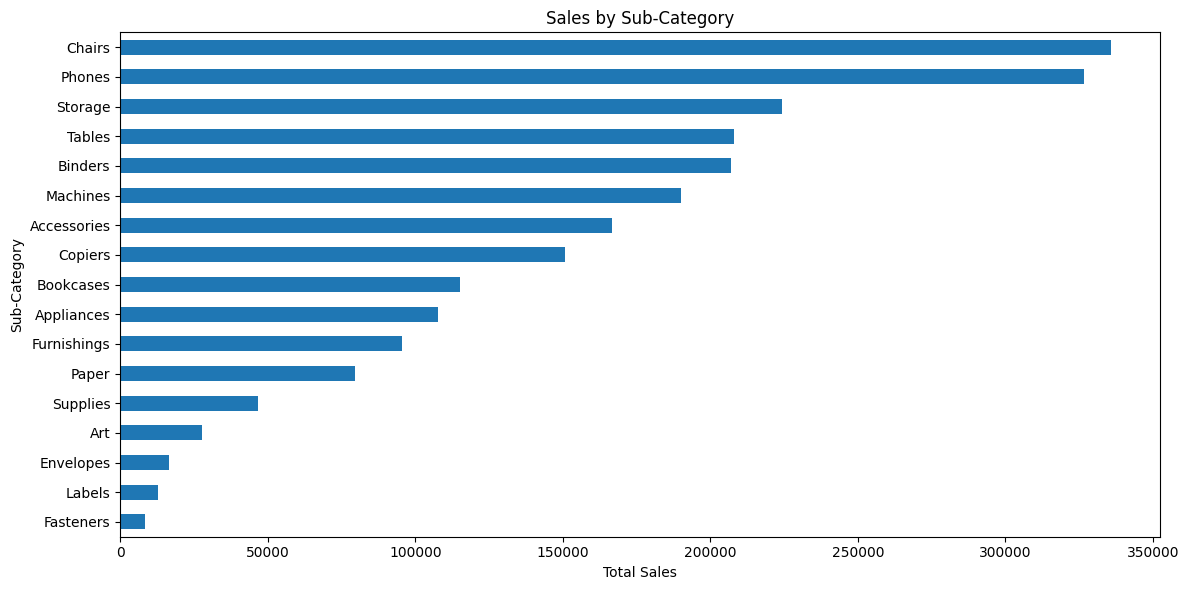

In [28]:
sales_by_subcategory = df.groupby(
    'Sub-Category'
)['Sales'].sum().sort_values()

plt.figure(figsize=(12, 6))

sales_by_subcategory.plot(kind='barh')

plt.title('Sales by Sub-Category')
plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')

plt.tight_layout()
plt.show()

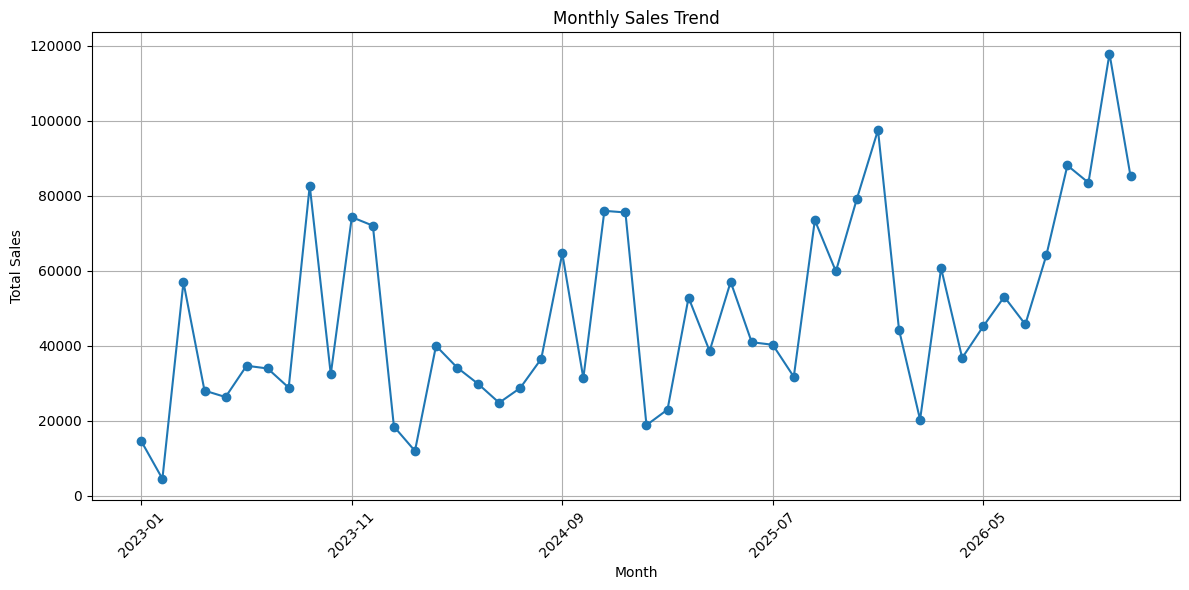

In [29]:
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 6))

monthly_sales.plot(
    kind='line',
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

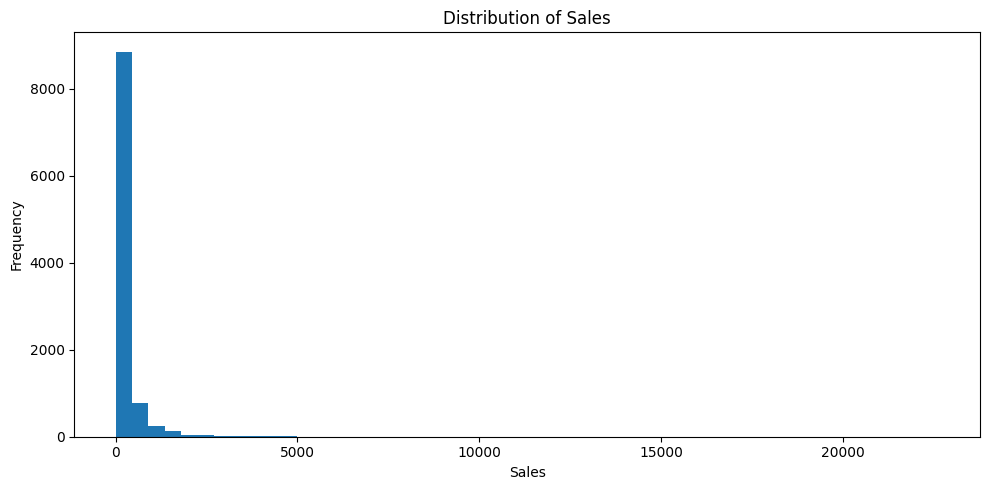

In [30]:
plt.figure(figsize=(10, 5))

df['Sales'].plot(
    kind='hist',
    bins=50
)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [31]:
print("Final Cleaned Dataset")

display(df.head(10))

print("Final Rows and Columns:", df.shape)

Final Cleaned Dataset


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2046,US-2023-133592,2023-12-31,2024-01-07,Standard Class,KM-16375,Katherine Murray,Home Office,United States,Providence,...,2908,East,OFF-PA-10003228,Office Supplies,Paper,Xerox 1917,195.64,4,0.0,91.9508
1,4701,US-2025-101525,2025-05-01,2025-05-04,Second Class,CM-12235,Chris McAfee,Consumer,United States,Little Rock,...,72209,South,OFF-PA-10001497,Office Supplies,Paper,Xerox 1914,109.92,2,0.0,53.8608
2,4964,US-2025-167472,2025-06-06,2025-06-07,First Class,CK-12595,Clytie Kelty,Consumer,United States,Little Rock,...,72209,South,TEC-AC-10003174,Technology,Accessories,Plantronics S12 Corded Telephone Headset System,323.37,3,0.0,129.3480
3,34,US-2023-103366,2023-01-15,2023-01-17,First Class,EH-13990,Erica Hackney,Consumer,United States,Roswell,...,30076,South,TEC-AC-10003628,Technology,Accessories,Logitech 910-002974 M325 Wireless Mouse for We...,149.95,5,0.0,65.9780
4,2927,US-2024-124219,2024-08-07,2024-08-08,First Class,KW-16570,Kelly Williams,Consumer,United States,Kirkwood,...,63122,Central,FUR-FU-10000305,Furniture,Furnishings,"Tenex V2T-RE Standard Weight Series Chair Mat,...",212.94,3,0.0,34.0704
5,4794,US-2025-141180,2025-05-15,2025-05-19,Second Class,DP-13000,Darren Powers,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-BI-10000301,Office Supplies,Binders,GBC Instant Report Kit,7.764,4,0.7,-5.1760
6,3318,US-2024-156510,2024-09-25,2024-09-29,Standard Class,EH-13990,Erica Hackney,Consumer,United States,Meriden,...,6450,East,OFF-PA-10002222,Office Supplies,Paper,"Xerox Color Copier Paper, 11"" x 17"", Ream",45.68,2,0.0,21.0128
7,4242,US-2025-155180,2025-01-22,2025-01-29,Standard Class,TB-21280,Toby Braunhardt,Consumer,United States,New York City,...,10009,East,OFF-BI-10004506,Office Supplies,Binders,Wilson Jones data.warehouse D-Ring Binders wit...,26.336,4,0.2,9.2176
8,9539,US-2026-132444,2026-11-18,2026-11-21,First Class,CD-12280,Christina DeMoss,Consumer,United States,Seattle,...,98105,West,TEC-AC-10003832,Technology,Accessories,Imation 16GB Mini TravelDrive USB 2.0 Flash Drive,132.52,4,0.0,54.3332
9,305,US-2023-128685,2023-04-04,2023-04-05,First Class,MZ-17515,Mary Zewe,Corporate,United States,Los Angeles,...,90008,West,OFF-BI-10004140,Office Supplies,Binders,Avery Non-Stick Binders,7.184,2,0.2,2.2450


Final Rows and Columns: (10165, 21)
